In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

import lightgbm as lgb
import xgboost as xgb
import shap

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score

/Users/tam_pr/research/eda/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("/Users/tam_pr/research/eda/data_processing/cleaned_df.csv")

In [4]:
df 

,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,ZP,...,Ce,La,Conc,AA,group_id,Material_CL1,Material_CL10,Material_CL5,Method_DPPH,Method_H2O2
0,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,39.04,...,26.742845,0.000000,5,41.142363,5,0,0,0,1,0
1,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,39.04,...,26.742845,0.000000,5,41.077538,5,0,0,0,1,0
2,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,39.04,...,26.742845,0.000000,20,58.634350,6,0,0,0,1,0
3,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,39.04,...,26.742845,0.000000,20,58.439875,6,0,0,0,1,0
4,172.1148,0.011620,0.011620,0.000000,5.045702,0.00000,0.528725,8.957388,3.10,39.04,...,26.742845,0.000000,20,58.688371,6,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,28.91,...,23.528019,1.933542,100,84.171000,43,0,1,0,0,1
171,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,28.91,...,23.528019,1.933542,100,84.993000,43,0,1,0,0,1
172,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,28.91,...,23.528019,1.933542,250,84.805100,44,0,1,0,0,1
173,171.9932,0.011628,0.010466,0.001163,4.544342,0.50352,0.529250,5.687981,3.09,28.91,...,23.528019,1.933542,250,84.758100,44,0,1,0,0,1


In [5]:
X= df.copy()
X.drop(columns=["group_id","AA"], inplace=True)
y = df["AA"].copy()


In [6]:
X.shape

(175, 24)

In [7]:
y.shape

(175,)

In [8]:
splitter = GroupShuffleSplit(n_splits=1, test_size= 0.2, random_state= 1234)
train_indices, test_indices = next(splitter.split(X = X, y = y, groups = df["group_id"]))
X_train , X_test = X.iloc[train_indices], X.iloc[test_indices]
y_train , y_test = y.iloc[train_indices], y.iloc[test_indices]


In [9]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(139, 24)
(36, 24)
(139,)
(36,)


In [10]:
group_id_train = df["group_id"].iloc[train_indices]

#### Cross Validation

In [11]:
folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups= group_id_train))

In [12]:
len(folds)

5

#### Now that we have succesfully splitted our training data into 5 folds, we can now begin to test the four selected models

In [13]:
all_mean_maes = []
all_mean_r2 = []

## RandomForestRegressor

#### For learning purposes, Cross Validation will be done manually and with the built-in functions of the libraries <br>
#### Manual CV

In [59]:
rf_r2= []
rf_mae = []

In [60]:
for fold_train_idx, fold_val_idx in folds: 
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model = RandomForestRegressor(random_state = 1234)

    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict(X_fold_val)

    rf_r2.append(r2_score(y_fold_val,y_pred))
    rf_mae.append(mean_absolute_error(y_fold_val,y_pred))


print("R^2 per fold: ", rf_r2)
print("Mean R^2", sum(rf_r2)/len(rf_r2))
all_mean_r2.append(sum(rf_r2)/len(rf_r2))

print("MAE per fold: ", rf_mae)
print("Mean MAE: ", sum(rf_mae)/ len(rf_mae))
all_mean_maes.append(sum(rf_mae)/ len(rf_mae))

rf_std_r2 = np.std(rf_r2)
rf_std_mae = np.std(rf_mae)

print("Standard deviation of the R^2 values: ", rf_std_r2)
print("Standard deviation of the MAE values: ", rf_std_mae)

R^2 per fold:  [0.8992393060182587, 0.5499120743057202, 0.8816074589510693, 0.9229273067931477, 0.9868197299432734]
Mean R^2 0.8481011752022939
MAE per fold:  [3.1011176146825923, 8.623634733047457, 5.40934333835129, 3.0987913134234963, 1.5412514395496584]
Mean MAE:  4.354827687810898
Standard deviation of the R^2 values:  0.15329468794827109
Standard deviation of the MAE values:  2.4657795713616952


#### Library CV

In [61]:
cv = GroupKFold(n_splits=5)

In [62]:
r2_scores_1 = cross_val_score(
    model, X_train, y_train,
    groups = group_id_train, 
    cv = cv, 
    scoring ="r2"
)

mae_scores_1 = -cross_val_score(
    model, X_train, y_train, 
    groups = group_id_train, 
    cv = cv, 
    scoring="neg_mean_absolute_error"
)

print("R^2 per fold: ", r2_scores_1)
print("Mean R^2: ", r2_scores_1.mean())

print("MAE per fold: ", mae_scores_1)
print("Mean MAE: ", mae_scores_1.mean())

rf_std_r2 = np.std(r2_scores_1)
rf_std_mae= np.std(mae_scores_1)

print("Standard deviation of the R^2 values: ", rf_std_r2)
print("Standard deviation of the MAE values: ", rf_std_mae)



R^2 per fold:  [0.89923931 0.54991207 0.88160746 0.92292731 0.98681973]
Mean R^2:  0.8481011752022939
MAE per fold:  [3.10111761 8.62363473 5.40934334 3.09879131 1.54125144]
Mean MAE:  4.354827687810898
Standard deviation of the R^2 values:  0.15329468794827109
Standard deviation of the MAE values:  2.4657795713616952


#### Comparative charts <br>

#### Just to check the manual loop is working correctly 

In [63]:
results_rf = pd.DataFrame({
    "Model":["Random Forest"]*5,
    "Fold": range(1, 6),
    "Manual R^2": rf_r2,
    "Library R^2": r2_scores_1,
    "Manual MAE": rf_mae,
    "Library MAE": mae_scores_1
})

print(results_rf.round(4).to_string(index=False))

        Model  Fold  Manual R^2  Library R^2  Manual MAE  Library MAE
Random Forest     1      0.8992       0.8992      3.1011       3.1011
Random Forest     2      0.5499       0.5499      8.6236       8.6236
Random Forest     3      0.8816       0.8816      5.4093       5.4093
Random Forest     4      0.9229       0.9229      3.0988       3.0988
Random Forest     5      0.9868       0.9868      1.5413       1.5413


#### Now that we are certain both the CVs did the same job, we can now just do a scatter plot to compare the performance of the model in each fold against the actual data 

## Extra Trees Regressor 

#### Manual CV

In [64]:
etr_r2= []
etr_mae = []

In [65]:
for fold_train_idx, fold_val_idx in folds: 
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model = ExtraTreesRegressor(random_state = 1234)

    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict(X_fold_val)

    etr_r2.append(r2_score(y_fold_val,y_pred))
    etr_mae.append(mean_absolute_error(y_fold_val,y_pred))


print("R^2 per fold: ", etr_r2)
print("Mean R^2", sum(etr_r2)/len(rf_r2))
all_mean_r2.append(sum(etr_r2)/len(etr_r2))

print("MAE per fold: ", etr_mae)
print("Mean MAE: ", sum(etr_mae)/ len(rf_mae))
all_mean_maes.append(sum(etr_mae)/ len(etr_mae))

etr_std_r2 = np.std(etr_r2)
etr_std_mae = np.std(etr_mae)

print("Standard deviation of the R^2 values: ", etr_std_r2)
print("Standard deviation of the MAE values: ", etr_std_mae)

R^2 per fold:  [0.875936526098078, 0.6687903028734876, 0.8424660735344391, 0.9332513166089005, 0.9919089284716671]
Mean R^2 0.8624706295173145
MAE per fold:  [3.2719945978134657, 6.387092372142682, 6.701328590720227, 2.7842412113214516, 1.0678295645904368]
Mean MAE:  4.0424972673176525
Standard deviation of the R^2 values:  0.10941458811420775
Standard deviation of the MAE values:  2.1721897163778663


In [66]:
cv = GroupKFold(n_splits=5)

In [67]:
r2_scores_2 = cross_val_score(
    model, X_train, y_train,
    groups = group_id_train, 
    cv = cv, 
    scoring ="r2"
)

mae_scores_2 = -cross_val_score(
    model, X_train, y_train, 
    groups = group_id_train, 
    cv = cv, 
    scoring="neg_mean_absolute_error"
)

print("R^2 per fold: ", r2_scores_2)
print("Mean R^2: ", r2_scores_2.mean())

print("MAE per fold: ", mae_scores_2)
print("Mean MAE: ", mae_scores_2.mean())

etr_std_r2 = np.std(r2_scores_2)
etr_std_mae = np.std(mae_scores_2)

print("Standard deviation of the R^2 values: ", etr_std_r2)
print("Standard deviation of the MAE values: ", etr_std_mae)

R^2 per fold:  [0.87593653 0.6687903  0.84246607 0.93325132 0.99190893]
Mean R^2:  0.8624706295173145
MAE per fold:  [3.2719946  6.38709237 6.70132859 2.78424121 1.06782956]
Mean MAE:  4.042497267317652
Standard deviation of the R^2 values:  0.10941458811420775
Standard deviation of the MAE values:  2.1721897163778663


In [ ]:
results_etr = pd.DataFrame({
    "Model":["Extra Trees Regressor"]*5,
    "Fold": range(1, 6),
    "Manual R^2": etr_r2,
    "Library R^2": r2_scores_2,
    "Manual MAE": etr_mae,
    "Library MAE": mae_scores_2
})

print(results_etr.round(4).to_string(index=False))

                Model  Fold  Manual R^2  Library R^2  Manual MAE  Library MAE
Extra Trees Regressor     1      0.8759       0.8759      3.2720       3.2720
Extra Trees Regressor     2      0.6688       0.6688      6.3871       6.3871
Extra Trees Regressor     3      0.8425       0.8425      6.7013       6.7013
Extra Trees Regressor     4      0.9333       0.9333      2.7842       2.7842
Extra Trees Regressor     5      0.9919       0.9919      1.0678       1.0678


## Gradient Boosting <br>
#### Manual CV

In [69]:
gb_r2= []
gb_mae = []

In [70]:
for fold_train_idx, fold_val_idx in folds: 
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model = GradientBoostingRegressor(random_state = 1234)

    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict(X_fold_val)

    gb_r2.append(r2_score(y_fold_val,y_pred))
    gb_mae.append(mean_absolute_error(y_fold_val,y_pred))


print("R^2 per fold: ", gb_r2)
print("Mean R^2", sum(gb_r2)/len(gb_r2))
all_mean_r2.append(sum(gb_r2)/len(gb_r2))

print("MAE per fold: ", gb_mae)
print("Mean MAE: ", sum(gb_mae)/ len(gb_mae))
all_mean_maes.append(sum(gb_mae)/ len(gb_mae))


gb_std_r2 = np.std(gb_r2)
gb_std_mae = np.std(gb_mae)

print("Standard deviation of the R^2 values: ", gb_std_r2)
print("Standard deviation of the MAE values: ", gb_std_mae)

R^2 per fold:  [0.8813077054872339, 0.6779454886143079, 0.8391805260716273, 0.9538260278885085, 0.9479309544530761]
Mean R^2 0.8600381405029507
MAE per fold:  [4.7982435979041105, 5.842610552453266, 7.690739628415509, 2.6549703389492123, 2.559512334610944]
Mean MAE:  4.709215290466608
Standard deviation of the R^2 values:  0.10056488742154714
Standard deviation of the MAE values:  1.9505457367849597


#### Library CV

In [71]:
cv = GroupKFold(n_splits=5)

In [72]:
r2_scores_3 = cross_val_score(
    model, X_train, y_train,
    groups = group_id_train, 
    cv = cv, 
    scoring ="r2"
)

mae_scores_3 = -cross_val_score(
    model, X_train, y_train, 
    groups = group_id_train, 
    cv = cv, 
    scoring="neg_mean_absolute_error"
)

print("R^2 per fold: ", r2_scores_3)
print("Mean R^2: ", r2_scores_3.mean())

print("MAE per fold: ", mae_scores_3)
print("Mean MAE: ", mae_scores_3.mean())

gb_std_r2 = np.std(r2_scores_3)
gb_std_mae = np.std(mae_scores_3)

print("Standard deviation of the R^2 values: ", gb_std_r2)
print("Standard deviation of the MAE values: ", gb_std_mae)

R^2 per fold:  [0.88130771 0.67794549 0.83918053 0.95382603 0.94793095]
Mean R^2:  0.8600381405029507
MAE per fold:  [4.7982436  5.84261055 7.69073963 2.65497034 2.55951233]
Mean MAE:  4.709215290466608
Standard deviation of the R^2 values:  0.10056488742154714
Standard deviation of the MAE values:  1.9505457367849597


In [73]:
results_gb = pd.DataFrame({
    "Model":["Gradient Boosting"]*5,
    "Fold": range(1, 6),
    "Manual R^2": gb_r2,
    "Library R^2": r2_scores_3,
    "Manual MAE": gb_mae,
    "Library MAE": mae_scores_3
})

print(results_gb.round(4).to_string(index=False))

            Model  Fold  Manual R^2  Library R^2  Manual MAE  Library MAE
Gradient Boosting     1      0.8813       0.8813      4.7982       4.7982
Gradient Boosting     2      0.6779       0.6779      5.8426       5.8426
Gradient Boosting     3      0.8392       0.8392      7.6907       7.6907
Gradient Boosting     4      0.9538       0.9538      2.6550       2.6550
Gradient Boosting     5      0.9479       0.9479      2.5595       2.5595


## LightGBM <br>
#### Manual CV

In [74]:
lgbm_r2= []
lgbm_mae = []

In [75]:
for fold_train_idx, fold_val_idx in folds: 
    X_fold_train = X_train.iloc[fold_train_idx]
    y_fold_train = y_train.iloc[fold_train_idx]

    X_fold_val = X_train.iloc[fold_val_idx]
    y_fold_val = y_train.iloc[fold_val_idx]

    model = LGBMRegressor(random_state = 1234, verbose = -1)

    model.fit(X_fold_train, y_fold_train)

    y_pred = model.predict(X_fold_val)

    lgbm_r2.append(r2_score(y_fold_val,y_pred))
    lgbm_mae.append(mean_absolute_error(y_fold_val,y_pred))


print("R^2 per fold: ", lgbm_r2)
print("Mean R^2", sum(lgbm_r2)/len(lgbm_r2))
all_mean_r2.append(sum(lgbm_r2)/len(lgbm_r2))


print("MAE per fold: ", lgbm_mae)
print("Mean MAE: ", sum(lgbm_mae)/ len(lgbm_mae))
all_mean_maes.append(sum(lgbm_mae)/ len(lgbm_mae))

lgbm_std_r2 = np.std(lgbm_r2)
lgbm_std_mae = np.std(lgbm_mae)

print("Standard deviation of the R^2 values: ", lgbm_std_r2)
print("Standard deviation of the MAE values: ", lgbm_std_mae)

R^2 per fold:  [0.9354187537638258, 0.6275113894579043, 0.8465822068854744, 0.9051849515862349, 0.9303626894460425]
Mean R^2 0.8490119982278964
MAE per fold:  [3.1959692538397126, 7.5741416248486, 7.396957983570417, 3.723697630161098, 3.2374425639300455]
Mean MAE:  5.025641811269975
Standard deviation of the R^2 values:  0.1151589220376423
Standard deviation of the MAE values:  2.0178408537418235


#### Library CV

In [76]:
cv = GroupKFold(n_splits=5)

In [77]:
r2_scores_4 = cross_val_score(
    model, X_train, y_train,
    groups = group_id_train, 
    cv = cv, 
    scoring ="r2"
)

mae_scores_4 = -cross_val_score(
    model, X_train, y_train, 
    groups = group_id_train, 
    cv = cv, 
    scoring="neg_mean_absolute_error"
)

print("R^2 per fold: ", r2_scores_4)
print("Mean R^2: ", r2_scores_4.mean())

print("MAE per fold: ", mae_scores_4)
print("Mean MAE: ", mae_scores_4.mean())
lgbm_std_r2 = np.std(r2_scores_4)
lgbm_std_mae = np.std(mae_scores_4)

print("Standard deviation of the R^2 values: ", lgbm_std_r2)
print("Standard deviation of the MAE values: ", lgbm_std_mae)

R^2 per fold:  [0.93541875 0.62751139 0.84658221 0.90518495 0.93036269]
Mean R^2:  0.8490119982278964
MAE per fold:  [3.19596925 7.57414162 7.39695798 3.72369763 3.23744256]
Mean MAE:  5.025641811269975
Standard deviation of the R^2 values:  0.1151589220376423
Standard deviation of the MAE values:  2.0178408537418235


In [78]:
results_lgbm = pd.DataFrame({
    "Model":["LightGBM"]*5,
    "Fold": range(1, 6),
    "Manual R^2": lgbm_r2,
    "Library R^2": r2_scores_4,
    "Manual MAE": lgbm_mae,
    "Library MAE": mae_scores_4
})

print(results_lgbm.round(4).to_string(index=False))

   Model  Fold  Manual R^2  Library R^2  Manual MAE  Library MAE
LightGBM     1      0.9354       0.9354      3.1960       3.1960
LightGBM     2      0.6275       0.6275      7.5741       7.5741
LightGBM     3      0.8466       0.8466      7.3970       7.3970
LightGBM     4      0.9052       0.9052      3.7237       3.7237
LightGBM     5      0.9304       0.9304      3.2374       3.2374


#### Using the means of the metrics we used to evaluate our models (Mean absolute Error and R^2), we can now choose the model that fits better our data


In [81]:
results =pd.concat([results_rf, results_etr, results_gb, results_lgbm], ignore_index=True)
results = results.drop(columns =["Manual R^2", "Manual MAE"])

results = results.rename(columns={    
    "Library R^2": "R^2",
    "Library MAE": "MAE"
})
results

,Model,Fold,R^2,MAE
0,Random Forest,1,0.899239,3.101118
1,Random Forest,2,0.549912,8.623635
2,Random Forest,3,0.881607,5.409343
3,Random Forest,4,0.922927,3.098791
4,Random Forest,5,0.986820,1.541251
5,Extra Trees Regressor,1,0.875937,3.271995
6,Extra Trees Regressor,2,0.668790,6.387092
7,Extra Trees Regressor,3,0.842466,6.701329
8,Extra Trees Regressor,4,0.933251,2.784241
9,Extra Trees Regressor,5,0.991909,1.067830


In [86]:
summary = results.groupby("Model").agg(
    **{
        "Mean R^2": ("R^2", "mean"),
        "Std R^2": ("R^2", "std"),
        "Mean MAE": ("MAE", "mean"),
        "Std MAE": ("MAE", "std")
    }
).reset_index()

summary

,Model,Mean R^2,Std R^2,Mean MAE,Std MAE
0,Extra Trees Regressor,0.862471,0.122329,4.042497,2.428582
1,Gradient Boosting,0.860038,0.112435,4.709215,2.180776
2,LightGBM,0.849012,0.128752,5.025642,2.256015
3,Random Forest,0.848101,0.171389,4.354828,2.756825


#### Extra Trees had the best mean R² and MAE, but differences between models are within fold-to-fold variation, so we proceed with it as the paper does

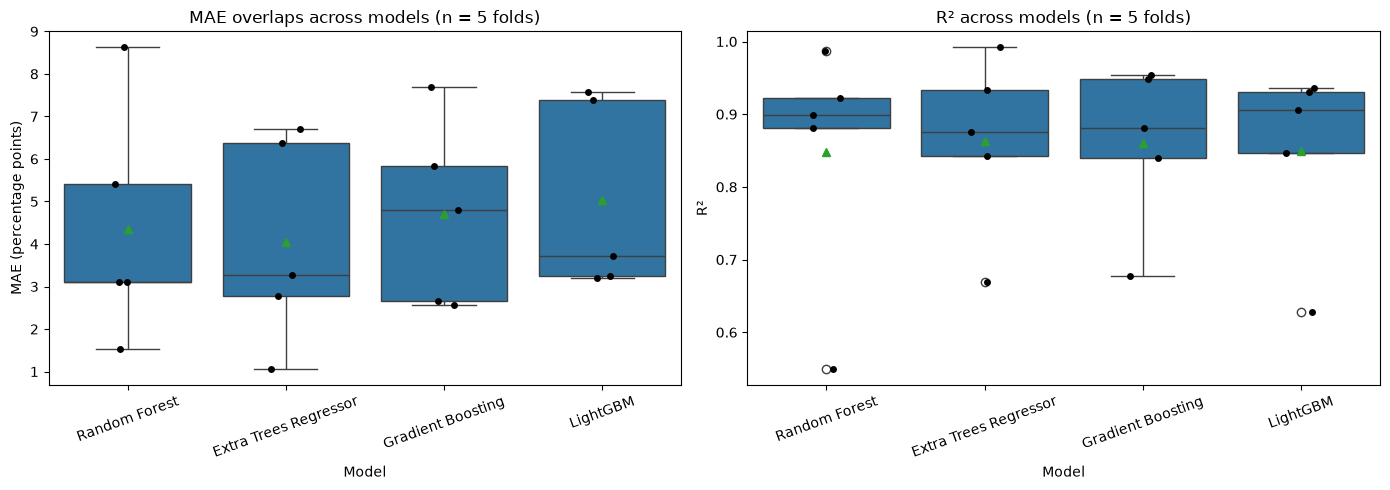

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=results, x="Model", y="MAE", showmeans=True, ax=axes[0])
sns.stripplot(data=results, x="Model", y="MAE", color="black", size=5, ax=axes[0])

axes[0].set_title("MAE overlaps across models (n = 5 folds)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("MAE (percentage points)")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=results, x="Model", y="R^2", showmeans=True, ax=axes[1])
sns.stripplot(data=results, x="Model", y="R^2", color="black", size=5, ax=axes[1])

axes[1].set_title("R² across models (n = 5 folds)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R²")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Model comparison (5-fold grouped CV on the training set)

Extra Trees had the best mean R² (0.862 ± 0.12) and MAE (4.04 ± 2.43 percentage points), followed by Gradient Boosting (0.860 / 4.71), LightGBM (0.849 / 5.03) and Random Forest (0.848 / 4.35). The MAE ranking (ET < RF < GB < LGBM) matches the paper’s. However, the gaps between models are much smaller than the fold-to-fold spread, so we can’t claim any model is clearly superior. We proceed with Extra Trees because it has the best mean on both metrics and it is the paper’s choice.

### Folds 2 and 3

In both boxplots, all four models struggle on the same folds. Fold 2 is the worst fold for every model on R² (0.55 to 0.68), and folds 2 and 3 are the two highest-MAE folds for all four models (up to about 8.6). Folds 4 and 5 are the easiest. Because the same folds are hard for every algorithm, the difficulty seems to come from which groups were held out, not from the model. This is why we report mean ± std over folds instead of a single split, and why one hold-out split earlier gave such unstable results.